In [57]:
import sys 
%load_ext autoreload
%autoreload 2

from spectrascope.SpectraScope import *
from spectrascope.Features import * 
from sklearn.linear_model import Ridge, Lasso, ElasticNet
import os

from matplotlib import gridspec
plt.style.use('../ss.mplstyle')


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


#### Load Data from Test Directory

Raw data from Ebrahimi repo : [here](https://github.com/imeb/Grape-Chemical-Composition/tree/main)

In [58]:
XSF_br = np.load('../tests/test_files/grapes_example/XSF_br.npy')
XRF_br = np.load('../tests/test_files/grapes_example/XRF_br.npy')
br = np.load('../tests/test_files/grapes_example/br.npy')
nir_wls = np.load('../tests/test_files/grapes_example/nir_xaxis.npy')
raman_wls = np.load('../tests/test_files/grapes_example/rm_xaxis.npy')

Text(0.5, 0.98, 'Raw Data')

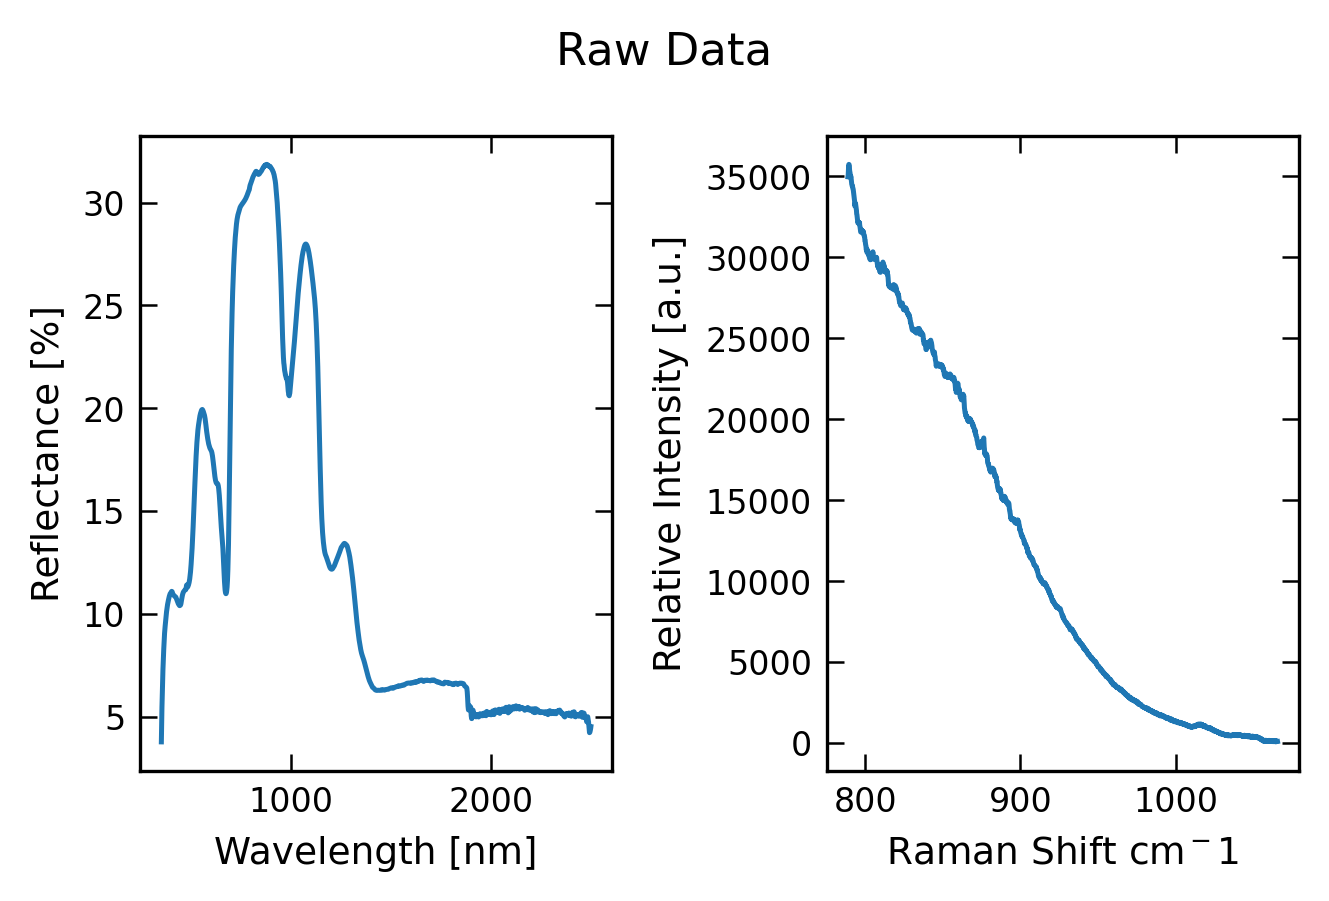

In [59]:
f, (ax1, ax2) = plt.subplots(1,2)
ax1.plot(nir_wls, XSF_br[0])
ax2.plot(raman_wls, XRF_br[0])

ax1.set_xlabel('Wavelength [nm]')
ax1.set_ylabel('Reflectance [%]')
ax2.set_xlabel(rf'Raman Shift $cm^{-1}$')
ax2.set_ylabel('Relative Intensity [a.u.]')
f.suptitle('Raw Data')


Center and scale the data as was done in Ebrahimi, et. al 

In [60]:
# Centering the data 

XSF_br_centered = np.zeros(XSF_br.shape)
for i,arr in enumerate(XSF_br): 
    arr = arr - np.mean(arr)
    XSF_br_centered[i] = arr

XRF_br_centered = np.zeros(XRF_br.shape)
for i,arr in enumerate(XRF_br): 
    arr = arr - np.mean(arr)
    XRF_br_centered[i] = arr


from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

XSF_br_centered_scaled = scaler.fit_transform(XSF_br_centered)
XRF_br_centered_scaled = scaler.fit_transform(XRF_br_centered)


#### Initialize spectrascope

In [61]:
# not using the centered and scaled data, but could 
XF = [XSF_br, XRF_br]

ss_f = SpectraScope(XF, br, specnames=['nir', 'rm'], yname='br', random_seed=10)
ss_f.add_x_axis('rm', raman_wls)
ss_f.add_x_axis('nir', nir_wls)

saving to /examples/models, change save_path kwarg if youd like to change


#### Add spectral features

In [62]:
ss_f.add_spectral_feature('rm', 'pointwise_features', xrange=ss_f.rm_xaxis)
ss_f.add_spectral_feature('rm', 'polynomial_featuresall')
ss_f.add_spectral_feature('rm', 'featureagg', n_clusters=15)
ss_f.add_spectral_feature('rm', 'pca', n_components=15)
ss_f.add_spectral_feature('rm', 'cdf')
ss_f.add_spectral_feature('rm', 'cwt')

ss_f.add_spectral_feature('nir', 'pointwise_features', xrange=ss_f.nir_xaxis)
ss_f.add_spectral_feature('nir', 'polynomial_featuresall')
ss_f.add_spectral_feature('nir', 'featureagg', n_clusters=15)
ss_f.add_spectral_feature('nir', 'pca', n_components=15)
ss_f.add_spectral_feature('nir', 'cdf')
ss_f.add_spectral_feature('nir', 'cwt')
ss_f.add_spectral_feature('nir', 'fft_features', xrange=ss_f.nir_xaxis)

#### Combine Modalities

In [64]:
ss_f.combine_feature('rm_pointwise_features', 'nir_pointwise_features')

#### Set up hyperparamter grid for cross validation

In [ ]:
from sklearn.metrics import root_mean_squared_error
from spectrascope.FusedLasso import FusedLasso
RF_kwargs = {'estimator':RandomForestRegressor(), 
                'param_grid':{'n_estimators':[50, 100, 200], 
                                        'criterion':['squared_error'],
                                        'max_depth': [50, None]},
                'refit':True,
                'scale_X':True, # Make sure False if input data is scaled and centered
                'metric':root_mean_squared_error}

lcen_kwargs = {'l1_ratio':[0.001, 0.01, 0.1,0.3, 0.5, 0.75,1], #was previously just 1
               'K_fold':5, 
               'cv_method':'Kfold', 
               'alpha':5, #change from 5 to 15
               'degree':[1],
               'trans_type':'poly', 
               'LCEN_cutoff':5e-5, 
               'LCEN_interaction':False, 
               'scale_X':True, # Make sure False if input data is scaled and centered
               'scale_y':True, #changed from True 
               'metric':root_mean_squared_error}


Lasso_kwargs = {'estimator':Lasso()}

fused_kwargs = {'estimator':FusedLasso(),
    'param_grid':{'alpha':[0.3,0.5,0.9],
                            'fit_intercept':[True]
                    },
                'refit':True,
                'metric':mean_squared_error
}

#### Train Random Forests

In [ ]:
feats = ['pointwise_features', 'cdf', 'featureagg', 'polynomial_featuresall', 'pca']#, 'pointwise_features_trans',] #uncomment for nonlinear transformations
from sklearn.metrics import root_mean_squared_error
for spec in ss_f.specnames:
    for feat in feats: 
        attr_name = f'{spec}_{feat}'
        ss_f.do_sk(attr_name, 'br', 0.25, use_pipeline=False, **RF_kwargs)
ss_f.do_sk('rm_nir_pointwise_features', 'br', 0.25, use_pipeline=False, **RF_kwargs)

already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted


/Users/amalyajohnson/miniconda3/envs/spec/lib/python3.12/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


RuntimeError: Optimization failed with status: user_limit

In [79]:
for spec in ss_f.specnames:
    for feat in feats: 
        attr_name = f'{spec}_{feat}'
        try: 
            ss_f.do_sk(attr_name, 'br', 0.25, use_pipeline=False, **fused_kwargs)
        except RuntimeError: 
            print(spec, feat)
            continue

already fitted


/Users/amalyajohnson/miniconda3/envs/spec/lib/python3.12/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


nir pointwise_features
already fitted


/Users/amalyajohnson/miniconda3/envs/spec/lib/python3.12/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


nir cdf
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted
already fitted


In [80]:
ss_f.do_sk('nir_pointwise_features', 'br', 0.25, use_pipeline=False, estimator=FusedLasso(alpha=0.5), metric=mean_squared_error)

/Users/amalyajohnson/miniconda3/envs/spec/lib/python3.12/site-packages/cvxpy/problems/problem.py:1539: UserWarning: Solution may be inaccurate. Try another solver, adjusting the solver settings, or solve with verbose=True for more information.
  warnings.warn(


#### Train LCEN 

In [130]:
feats_lcen = ['pointwise_features', 'cdf', 'featureagg', 'polynomial_featuresall', 'pca']

for spec in ss_f.specnames:
    for feat in feats_lcen: 
        attr_name = f'{spec}_{feat}'
        ss_f.do_LCEN(attr_name, 'br', 0.25, **lcen_kwargs)

ss_f.do_LCEN('rm_nir_pointwise_features', 'br', 0.25, **lcen_kwargs)

Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 42 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 1.1478 | Mean relative error = 0.0549
Test set : RMSE = 1.5645 | Mean relative error = 0.0757
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 42 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 1.1174 | Mean relative error = 0.0554
Test set : RMSE = 1.5382 | Mean relative error = 0.0745
Beginning variable selection runs. There are 6 hyperparameter combinations
Beginning real runs. There are 42 hyperparameter combinations
Completed model LCENf fold   5
The best model is LCEN. View its resul

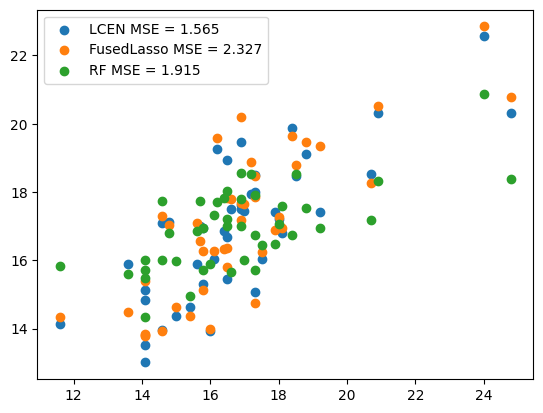

In [138]:
ypred = ss_f.nir_pointwise_features_br_LCEN['yhat_test_nontrans']
score = ss_f.nir_pointwise_features_br_LCEN['score']
plt.scatter(ss_f.br_test, ypred, label='LCEN' + ' MSE = ' + str(round(score,3)))

ypred = ss_f.nir_pointwise_features_br_FusedLasso['ypred']
score = ss_f.nir_pointwise_features_br_FusedLasso['score']
plt.scatter(ss_f.br_test, ypred, label='FusedLasso' + ' MSE = ' + str(round(score,3)))

ypred = ss_f.nir_pointwise_features_br_RandomForestRegressor['ypred']
score = ss_f.nir_pointwise_features_br_RandomForestRegressor['score']
plt.scatter(ss_f.br_test, ypred, label='RF' + ' MSE = ' + str(round(score,3)))
plt.legend()

In [113]:
coefs = ss_f.nir_pointwise_features_br_FusedLasso['P'].coef_
flips = np.argwhere(np.abs(np.diff(coefs)) > 5e-8)
flips = flips.reshape(len(flips),)
constant_B = np.zeros_like(coefs)
for i, flip in enumerate(flips):
    if i == 0 : 
        constant_B[:flip] = np.mean(coefs[:flip])
    elif (i > 0) and (i < len(flips)-1): 
        constant_B[flip:flips[i+1]] = np.mean(coefs[flip:flips[i+1]])
    else: 
        constant_B[flip:] = np.mean(coefs[flip:])

Utility Functions for Plotting 

In [141]:
import copy  
from PIL import Image
from spectrascope.SSPlotting import PlotModel as pm 
from spectrascope.SSPlotting import PlotSpectralFeatures as psf

results_df = copy.copy(pd.DataFrame(ss_f.best_fits).T)
labels = [
    'NIR, Intensity',
    'NIR, CDF',
    'NIR, Clustering',
    'NIR, Polynomial',
    'NIR, PCA',
    'Raman, Intensity',
    'Raman, CDF',
    'Raman, Clustering',
    'Raman, Polynomial',
    'Raman, PCA',
    'Raman & NIR, Intensity'
]

to_plot = ['pointwise_features', 'cdf', 'featureagg', 'polynomial_featuresall', 'pca']
to_plot_nicenames = {'pointwise_features':'Interpolated Data', 
                     'cdf':'CDF', 
                     'featureagg':'Clustering', 
                     'polynomial_featuresall':'Polynomial Fits', 
                     'pca':'PCA'}

ytrue = ss_f.br_test

from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from spectrascope.Features import SpectralFeatures
import os

def plot_spectral_features_matplotlib(xaxis, raw, selected_features, ax=None,zoom=0.1,
                                      plot_raw=True, print_centers=False):
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))
    
    # Plot the raw spectrum
    if plot_raw:
        ax.plot(xaxis, raw, color='black', lw=1)

    # Generate binned features
    temp = SpectralFeatures(xaxis, raw)
    for bins in [4, 5, 10, 20]:
        temp.generate_bins(bins)

    # Feature ID config
    feature_config = [
        (0, 16,  'bin_indices_4',  'const', 4),
        (16, 36, 'bin_indices_5',  'line',  5),
        (36, 76, 'bin_indices_10', 'par',   10),
        (76, 156, 'bin_indices_20', 'cubic', 20),
    ]

    def find_nearest(array, value):
        return np.abs(array - value).argmin()
    centers_used = []
    for selected_id in selected_features:
        for id_min, id_max, bin_label, poly_label, num_bins in feature_config:
            if id_min <= selected_id < id_max:
                search_bins = np.linspace(id_min, id_max, num_bins)
                located_bin = np.argwhere(selected_id < search_bins)[0][0]
                bin_mask = getattr(temp, bin_label) == located_bin
                center = np.median(xaxis[bin_mask])
                height_id = find_nearest(xaxis, center)
                height = raw[height_id]

                # Load image
                img_path = f"../app/static/{poly_label}.png"
                if not os.path.exists(img_path):
                    print(f"Warning: {img_path} not found.")
                    continue
                im = Image.open(img_path)

                # Convert image to matplotlib offsetbox
                imagebox = OffsetImage(im, zoom=zoom)
                if center in centers_used: 
                    add_to_height = 1  # slight offset to avoid overlap
                else: 
                    add_to_height = 0 
                ab = AnnotationBbox(imagebox, (center, height + add_to_height), frameon=False)
                centers_used.append(center)
                if print_centers: 
                    print(center, selected_id)

                ax.add_artist(ab)
                break  # stop after first matching range

    return ax


<Axes: >

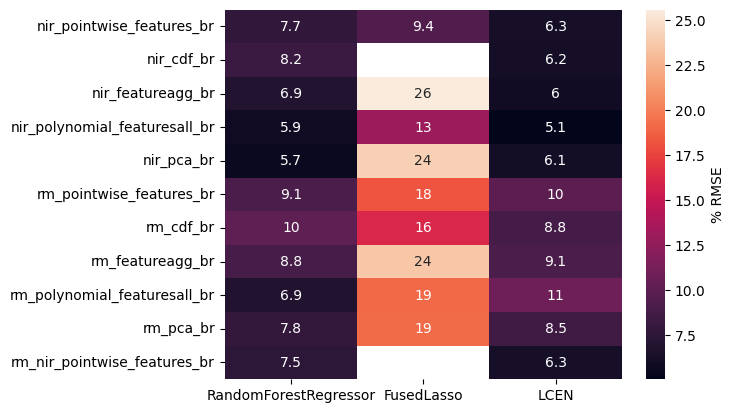

In [142]:
import seaborn as sns
sns.heatmap((results_df.T) / np.max(ss_f.br) * 100, annot=True, cbar_kws={'label': '% RMSE'})

In [152]:
corr = ss_f.pearson_feature_selection('br', ss_f.generated_features, return_vals=True, k=len(ss_f.generated_features))
corr_df = pd.DataFrame({'r':[np.abs(corr[key]).mean() for key in corr]}, index=[key for key in corr])

mif = ss_f.mutual_info_feature_selection('br', ss_f.generated_features, return_vals=True, k=len(ss_f.generated_features))
mif_df = pd.DataFrame({'MIF':[np.abs(mif[key]).mean() for key in mif]}, index=[key for key in mif])

merged = corr_df.merge(mif_df, left_index=True, right_index=True)
merged.to_csv('../JOSS/Figures/Grapes_corr.csv')

100%|██████████| 14/14 [00:19<00:00,  1.43s/it]


In [203]:
temp = pd.DataFrame(np.sqrt(results_df.T['LCEN']) / np.max(ss_f.br) * 100)
temp = temp.rename(index = lambda x : x.replace('_br', ''))

merged_err = merged.join(temp, how='inner')
merged_err.columns = ['r', 'MIF', '% RMSE']

In [204]:
PRETTY_LABELS_DICT = {
        'nir_pointwise_features':'NIR, Intensity', 'rm_pointwise_features':'Raman, Intensity',
        'nir_polynomial_featuresall': 'NIR, Polynomial', 
        'rm_polynomial_featuresall':'Raman, Polynomial',
        'nir_cdf':'NIR, CDF', 
        'rm_cdf':'Raman, CDF',
        'nir_pca':'NIR, PCA', 
        'rm_pca':'Raman, PCA',
        'nir_featureagg':'NIR, Clustering', 
        'rm_featureagg': 'Raman, Clustering',
        'nir_rm_pointwise_features':'NIR + Raman, Intensity', 
        'nir_rm_polynomial_featuresall':'NIR + Raman, Polynomial',
        'nir_cwt': 'NIR, CWT'
}

merged_err = merged_err.rename(PRETTY_LABELS_DICT, axis=0)

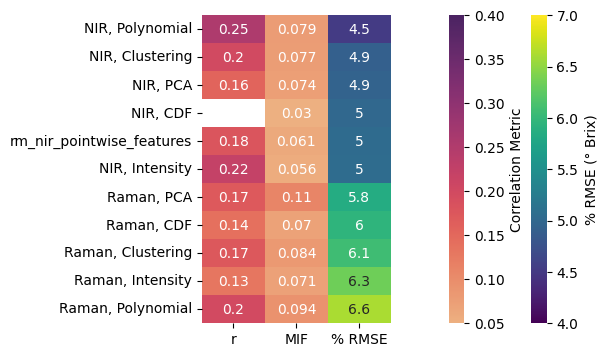

In [207]:
cmap1 = plt.get_cmap('viridis').copy()
cmap1.set_under('none')
cmap2 = plt.get_cmap('flare').copy()
cmap2.set_over('none')
f, ax1 = plt.subplots(1,1,figsize=(5,4))
ax1 = sns.heatmap(merged_err.sort_values('% RMSE'), vmin=4, vmax=7,annot=True, cmap=cmap1, cbar_kws={'pad':0.1})
sns.heatmap(merged_err.sort_values('% RMSE'), vmin=0.05, vmax=0.4, cmap=cmap2, ax=ax1, cbar_kws={'pad':0.2})
# ax1.set_yticklabels([PRETTY_LABELS_DICT[ind] for ind in merged_err.index])

# Add labels to colorbars for the two colorbars present
cbar1 = ax1.collections[0].colorbar
cbar2 = ax1.collections[1].colorbar
cbar1.set_label('% RMSE (° Brix)')
cbar2.set_label('Correlation Metric')

plt.savefig('/Users/amalyajohnson/Desktop/SpectraScope - 2025/Figures/Grapes_Correlation.pdf')
plt.savefig('/Users/amalyajohnson/Desktop/SpectraScope - 2025/Figures/Grapes_Correlation.svg')


#### Visualize the top two principal components for regressing Brixs 

Text(0.5, 1.0, 'NIR, PCA, LCEN')

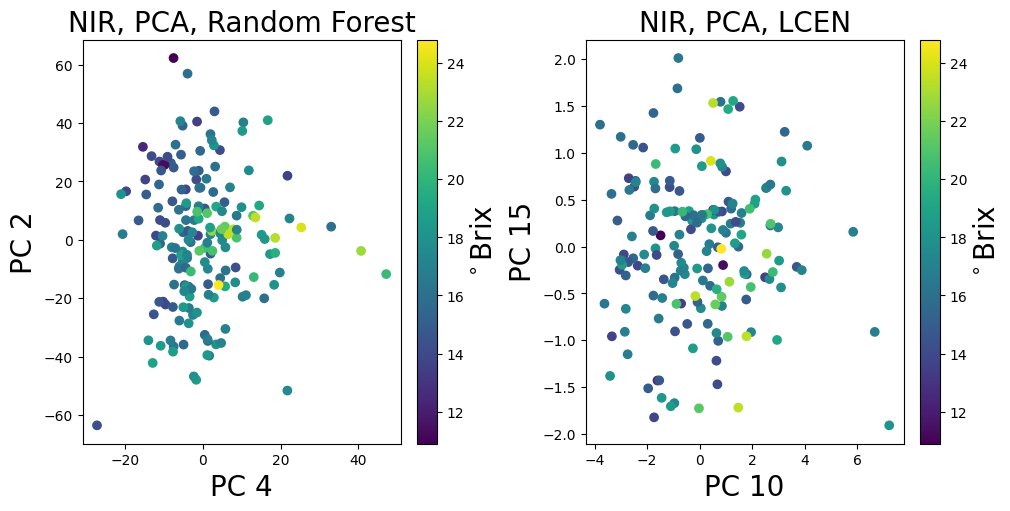

In [192]:
f, (ax1, ax2) = plt.subplots(1,2,figsize=(10,5), constrained_layout=True)
top_pca_rf = ss_f.nir_pca_br_RandomForestRegressor['selected_features'][:2]
top_pca = ss_f.nir_pca_br_LCEN['selected_features'][:2]

scatter1 = ax1.scatter(ss_f.nir_pca[:,top_pca_rf[0]], ss_f.nir_pca[:,top_pca_rf[1]], c=ss_f.br, cmap='viridis')
scatter2 = ax2.scatter(ss_f.nir_pca[:,top_pca[0]], ss_f.nir_pca[:,top_pca[1]], c=ss_f.br, cmap='viridis')

cb1 = plt.colorbar(scatter1)
cb2 = plt.colorbar(scatter2)

cb1.set_label(r'$^\circ$Brix', fontsize=20)
cb2.set_label(r'$^\circ$Brix', fontsize=20)

ax1.set_xlabel(f'PC {top_pca_rf[0]+1}', fontsize=20)
ax1.set_ylabel(f'PC {top_pca_rf[1]+1}', fontsize=20)
ax2.set_xlabel(f'PC {top_pca[0]+1}', fontsize=20)
ax2.set_ylabel(f'PC {top_pca[1]+1}', fontsize=20)

ax1.set_title('NIR, PCA, Random Forest', fontsize=20)
ax2.set_title('NIR, PCA, LCEN', fontsize=20)

#### Main Text Figure 4

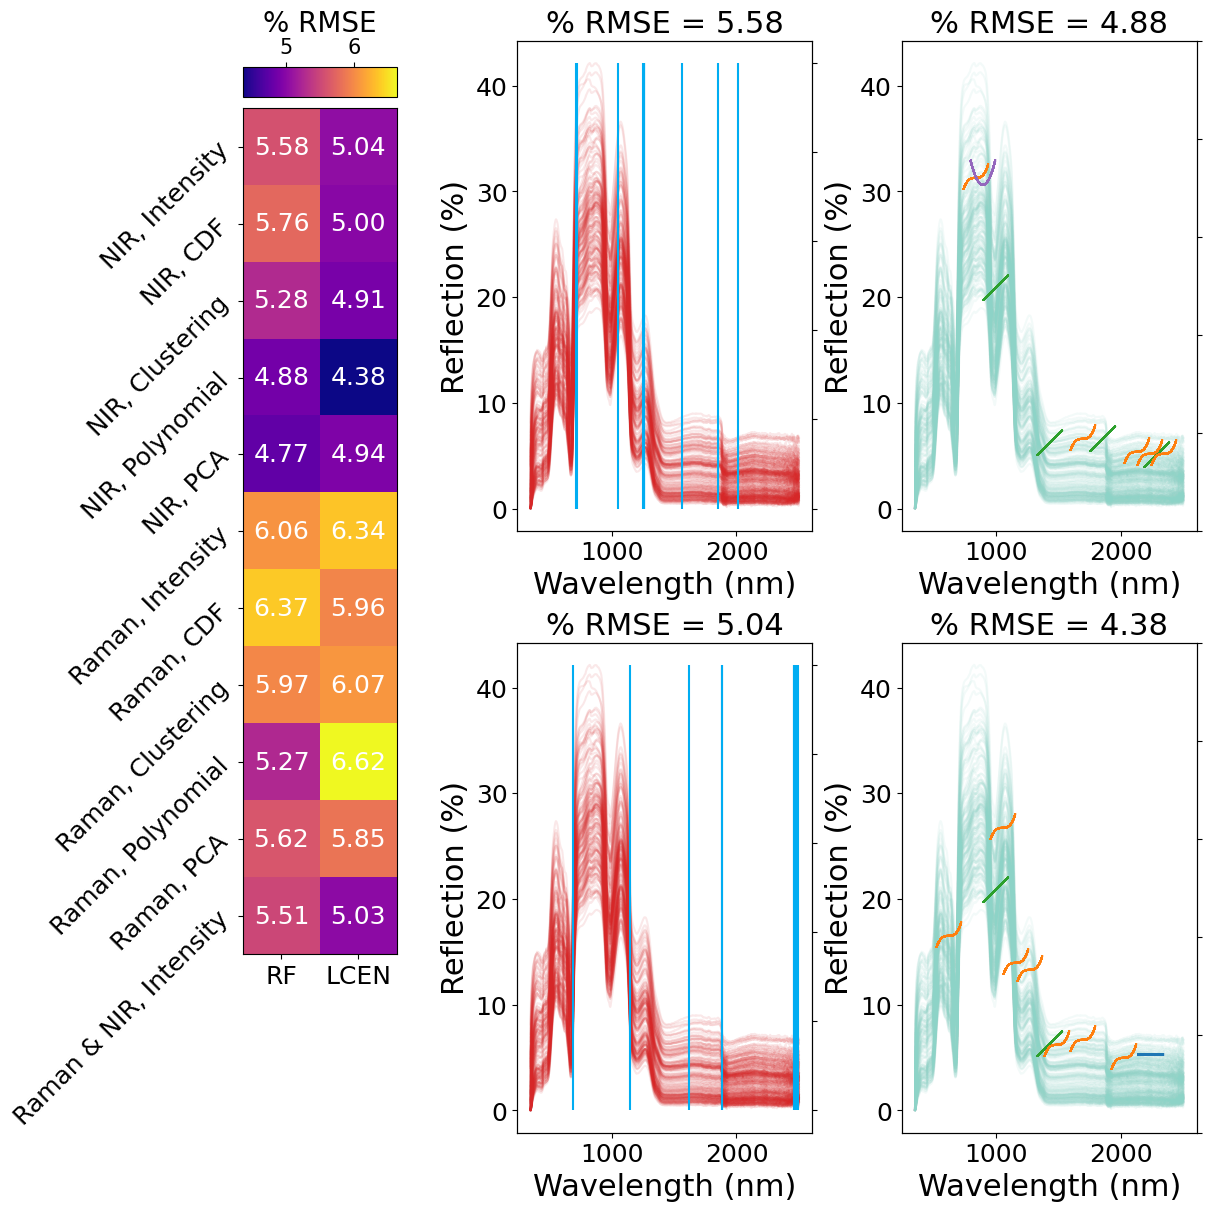

In [265]:
import matplotlib.gridspec as gridspec
fontsize = 22
ticklabelsize = 18


results_df = copy.copy(pd.DataFrame(ss_f.best_fits).T)

# Setting up the figure 
fig = plt.figure(figsize=(12, 12), constrained_layout=True)
outer_gs = gridspec.GridSpec(2,3, figure=fig, width_ratios=[1,2.5,2.5], height_ratios=[1, 1], hspace=0.5, wspace=0.2)
# First row: 3 subplots
ax1 = fig.add_subplot(outer_gs[:,0])
inner_top = gridspec.GridSpecFromSubplotSpec(2,1, subplot_spec=outer_gs[:,1], wspace=0.3)
ax4 = fig.add_subplot(inner_top[0])
ax2 = fig.add_subplot(inner_top[1])

inner_bottom = gridspec.GridSpecFromSubplotSpec(2,1, subplot_spec=outer_gs[:,2], wspace=0.3)
ax5 = fig.add_subplot(inner_bottom[0])
ax3 = fig.add_subplot(inner_bottom[1])

#Twin x axis for plotting the selected features 
ax2_twin = ax2.twinx()
ax3_twin = ax3.twinx()
ax4_twin = ax4.twinx()
ax5_twin = ax5.twinx()


prmse_df = (np.sqrt(results_df.T) / ss_f.br.max()) * 100  # percent RMSE
prmse_df = prmse_df[['RandomForestRegressor', 'LCEN']]
im = ax1.imshow(prmse_df, cmap='plasma')
ax1.set_yticks(np.arange(len(labels)));
ax1.set_yticklabels(labels, rotation=45, ha='right', size=18);
ax1.set_xticks([0, 1])
ax1.set_xticklabels(['RF', 'LCEN'], size=18)
cb1 = fig.colorbar(im, ax=ax1, location='top', aspect=5, pad=0.01)
cb1.ax.tick_params(labelsize=15)  # Tick label font size
cb1.set_label('% RMSE', fontsize=20)

for (i, j), val in np.ndenumerate(prmse_df):
    ax1.text(j, i, f'{val:.2f}', ha='center', va='center', color='white',size=ticklabelsize)

spec = 'nir'

for mn, axes in zip(['RandomForestRegressor', 'LCEN'], [(ax4, ax5, ax4_twin), (ax2, ax3, ax2_twin)]):
    ax_i, ax_ii, ax_twin = axes
    rmse = pd.DataFrame(ss_f.best_fits).T[['nir_pointwise_features_br', 'nir_polynomial_featuresall_br']].loc[mn].values
    subplot_titles=['', '']
    subplot_titles = [title + f'% RMSE = {round(100 * r / np.max(ss_f.br), 2)}' for title, r in zip(subplot_titles, np.sqrt(rmse))]
    ax_i.set_title(subplot_titles[0], fontsize=fontsize)
    ax_ii.set_title(subplot_titles[1], fontsize=fontsize)
    for spectrum in ss_f.nir_pointwise_features: 
        ax_i.plot(ss_f.nir_xaxis, spectrum, color='#d62728', alpha=0.1)
        ax_ii.plot(ss_f.nir_xaxis, spectrum, color=plt.cm.Set3(np.arange(10))[0], alpha=0.1)

    model = getattr(ss_f, f'{spec}_pointwise_features_br_{mn}')
    selected_features = model['selected_features'][:10]
    selected_vals = model['selected_vals']
    for i in selected_features:
        ax_twin.vlines(ss_f.nir_xaxis[i], 0, 1, color='#00ADF2', alpha=1)
    
plot_spectral_features_matplotlib(ss_f.nir_xaxis, ss_f.nir_pointwise_features[0], ss_f.nir_polynomial_featuresall_br_RandomForestRegressor['selected_features'][:10], ax=ax5,zoom=0.05, plot_raw=False)
plot_spectral_features_matplotlib(ss_f.nir_xaxis, ss_f.nir_pointwise_features[0], ss_f.nir_polynomial_featuresall_br_LCEN['selected_features'][:10], ax=ax3,zoom=0.05, plot_raw=False)


for ax in [ax2, ax3, ax4, ax5]:
    ax.set_xlabel('Wavelength (nm)',fontsize=fontsize)
    ax.set_ylabel('Reflection (%)',fontsize=fontsize)
    ax.tick_params(axis='both', labelsize=ticklabelsize)
    ax.xaxis.label.set_size(fontsize)
    ax.yaxis.label.set_size(fontsize)

for ax in [ax2_twin, ax3_twin, ax4_twin, ax5_twin]:
    ax.set_yticklabels([]);

plt.savefig(f"../JOSS/Figures/Fig4_120825.svg")
plt.savefig(f"../JOSS/Figures/Fig4_120825.pdf")

### What are the best LCEN model hyperparameters for the polynomial featurization scheme? 

In [212]:
ss_f.nir_polynomial_featuresall_br_LCEN['model_hyper']

{'degree': 1,
 'l1_ratio': 0.01,
 'alpha': 0.00707945784384138,
 'lag': 0,
 'cutoff': 5e-05,
 'trans_type': 'poly'}

### What are the number of features selected by the different LCEN models? 

In [213]:
print('poly features:',len(ss_f.nir_polynomial_featuresall_br_LCEN['model_params']))
print('num poly features:',len(ss_f.nir_polynomial_featuresall[0]))
print('pointwise features:',len(ss_f.nir_pointwise_features_br_LCEN['model_params']))
print('num pointwise features:',len(ss_f.nir_xaxis))

poly features: 43
num poly features: 157
pointwise features: 26
num pointwise features: 2151


In [240]:
all_selected = [int(x.replace('x', '')) for x in  np.array(ss_f.nir_pointwise_features_br_LCEN['model_params'])[1:,0]]
all_vals = [float(x) for x in  np.array(ss_f.nir_pointwise_features_br_LCEN['model_params'])[1:,1]]

### What is the sparsest LCEN model
Pointwise features -- 26 features 

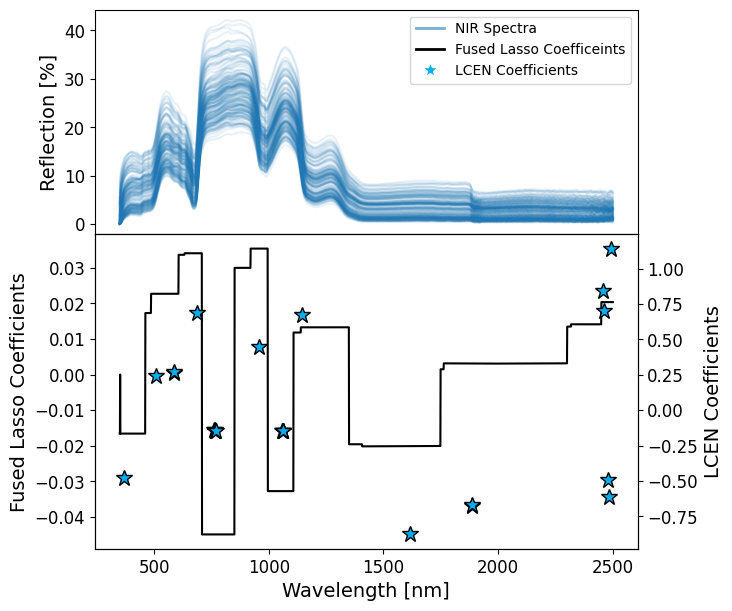

In [266]:
fontsize=14
for feat in ['nir_pointwise_features']:
    if hasattr(ss_f, feat + '_br_FusedLasso'):
        coefs = getattr(ss_f, feat + '_br_FusedLasso')['P'].coef_
        flips = np.argwhere(np.abs(np.diff(coefs)) > 5e-8)
        flips = flips.reshape(len(flips),)
        constant_B = np.zeros_like(coefs)
        for i, flip in enumerate(flips):
            if i == 0 : 
                constant_B[:flip] = np.mean(coefs[:flip])
            elif (i > 0) and (i < len(flips)-1): 
                constant_B[flip:flips[i+1]] = np.mean(coefs[flip:flips[i+1]])
            else: 
                constant_B[flip:] = np.mean(coefs[flip:])

        f, (ax1, ax2) = plt.subplots(2,1,gridspec_kw={'height_ratios': [0.5, 0.7]}, figsize=(7,7), sharex=True)
        # f.suptitle('NIR')
        # ax2.bar(ss_f.nir_xaxis, ss_f.nir_pointwise_features_br_FusedLasso['P'].coef_, alpha=0.1, color='k')
        for spec in ss_f.nir_pointwise_features: 
            ax1.plot(ss_f.nir_xaxis, spec, alpha=0.1, color='tab:blue')
        ax2.plot(ss_f.nir_xaxis, constant_B, color='k')
        # ax2.hlines(0, min(ss_f.nir_xaxis), max(ss_f.nir_xaxis), color='k', linestyle='--')
        ax1.set_ylabel('Reflection [%]', fontsize=fontsize)
        ax2.set_xlabel('Wavelength [nm]', fontsize=fontsize)
        ax2.set_ylabel('Fused Lasso Coefficients', fontsize=fontsize)

# plot_spectral_features_matplotlib(ss_f.nir_xaxis, ss_f.nir_pointwise_features[0], ss_f.nir_polynomial_featuresall_br_LCEN['selected_features'][:10], ax=ax1,zoom=0.04, plot_raw=False)
selected_features = ss_f.nir_pointwise_features_br_LCEN['selected_features']

selected_features = [int(x.replace('x', '')) for x in  np.array(ss_f.nir_pointwise_features_br_LCEN['model_params'])[1:,0]]
selected_vals = [float(x) for x in  np.array(ss_f.nir_pointwise_features_br_LCEN['model_params'])[1:,1]]

ax1_twin = ax2.twinx()
for i, index in enumerate(selected_features):
    ax1_twin.plot(ss_f.nir_xaxis[index], selected_vals[i], color='#00ADF2', alpha=1, markersize=12,marker='*', markeredgecolor='k')
ax1_twin.set_ylabel('LCEN Coefficients', fontsize=fontsize)
# Add legend, stars are the features from the polynomial model

from matplotlib.lines import Line2D

# Custom legend elements
legend_elements = [
    Line2D([0], [0], color='tab:blue', lw=2, alpha=0.6, label='NIR Spectra'),
    Line2D([0], [0], color='k', lw=2, label='Fused Lasso Coefficeints'),
    Line2D([0], [0], marker='*', color='w', markerfacecolor='#00ADF2', markersize=12, label='LCEN Coefficients')
]

ax1.legend(handles=legend_elements, loc='upper right', frameon=True)
ticksize=12
for ax in [ax1, ax2, ax1_twin]:
    ax.set_yticklabels(ax.get_yticklabels(), size=ticksize)
ax2.set_xticklabels(ax2.get_xticklabels(), size=ticksize);
plt.subplots_adjust(hspace=0, wspace=0)

plt.savefig(f"../JOSS/Figures/Fig5_120825.svg")
plt.savefig(f"../JOSS/Figures/Fig5_120825.pdf")

### Repeating LCEN with different fixed parameters but modifying the clip cutoff, the alpha parameter, or the l1 ratio 

### Vary Cutoff

In [259]:
nalpha = 5

bestalpha = 0.00707945784384138
cutoff_used = 5e-5
alpharange = np.round(np.concatenate(([0], np.logspace(-4.3, 0, nalpha))), 7)
cutoff_arr = [1,5e-1,3e-1, 1e-1, 7e-2, 5e-2,3e-2, 1e-2, 5e-3,5e-4,5e-5]
results = []
for cutoff in cutoff_arr: 
    lcen_elbow_kwargs = {'l1_ratio':[0.01],
               'cv_method':None, 
               'degree': [1],
               'alpha': [bestalpha],
               'LCEN_cutoff': cutoff,
               'lag':[0],
               'trans_type': 'poly',
               'LCEN_interaction':False, 
               'scale_X':True, # Make sure False if input data is scaled and centered
               'scale_y':True, #changed from True 
               'metric':root_mean_squared_error}
    
    ss_f.do_LCEN('nir_polynomial_featuresall', 'br', 0.25, **lcen_elbow_kwargs)
    prmse = ss_f.nir_polynomial_featuresall_br_LCEN['score'] / np.max(ss_f.br) * 100
    results.append(prmse)

CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperparameter combinations
Beginning real runs. There are 1 hyperparameter combinations
Completed model LCENf fold  50
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 2.4375 | Mean relative error = 0.1114
Test set : RMSE = 2.4709 | Mean relative error = 0.1054
CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperparameter combinations
Beginning real runs. There are 1 hyperparameter combinations
Completed model LCENf fold  50
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 1.8892 | Mean relative error = 0.0889
Test set : RMSE = 2.3161 | Mean relative error = 0.1063
CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperpar

### Vary Alpha 

In [260]:
alpharange = np.round(np.concatenate(([0], np.logspace(-4.3, 0, nalpha))), 7)
alpharesults = []
for alph in alpharange: 
    lcen_elbow_kwargs = {'l1_ratio':[0.01],
               'cv_method':None, 
               'degree': [1],
               'alpha': [alph],
               'LCEN_cutoff': cutoff_used,
               'lag':[0],
               'trans_type': 'poly',
               'LCEN_interaction':False, 
               'scale_X':True, # Make sure False if input data is scaled and centered
               'scale_y':True, #changed from True 
               'metric':root_mean_squared_error}
    
    ss_f.do_LCEN('nir_polynomial_featuresall', 'br', 0.25, **lcen_elbow_kwargs)
    prmse = ss_f.nir_polynomial_featuresall_br_LCEN['score'] / np.max(ss_f.br) * 100
    alpharesults.append(prmse)

CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperparameter combinations
Beginning real runs. There are 1 hyperparameter combinations
Completed model LCENf fold  50
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.4773 | Mean relative error = 0.0235
Test set : RMSE = 1.5296 | Mean relative error = 0.0738
CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperparameter combinations
Beginning real runs. There are 1 hyperparameter combinations
Completed model LCENf fold  50
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.4833 | Mean relative error = 0.0238
Test set : RMSE = 1.4717 | Mean relative error = 0.0709
CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperpar

### Vary L1 Ratio 

In [261]:

bestalpha = 0.00707945784384138
cutoff_used = 5e-5
l1_arr = [0.001, 0.01, 0.1,0.3, 0.5, 0.75,1]
lratio_results = []
for l1 in l1_arr: 
    lcen_elbow_kwargs = {'l1_ratio':[l1],
               'cv_method':None, 
               'degree': [1],
               'alpha': [bestalpha],
               'LCEN_cutoff': cutoff_used,
               'lag':[0],
               'trans_type': 'poly',
               'LCEN_interaction':False, 
               'scale_X':True, # Make sure False if input data is scaled and centered
               'scale_y':True, #changed from True 
               'metric':root_mean_squared_error}
    
    ss_f.do_LCEN('nir_polynomial_featuresall', 'br', 0.25, **lcen_elbow_kwargs)
    prmse = ss_f.nir_polynomial_featuresall_br_LCEN['score'] / np.max(ss_f.br) * 100
    lratio_results.append(prmse)

CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperparameter combinations
Beginning real runs. There are 1 hyperparameter combinations
Completed model LCENf fold  50
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.7341 | Mean relative error = 0.0363
Test set : RMSE = 1.2559 | Mean relative error = 0.0605
CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperparameter combinations
Beginning real runs. There are 1 hyperparameter combinations
Completed model LCENf fold  50
The best model is LCEN. View its results via fitting_result["LCEN"] or by opening the SPA_results json/pickle files.
Train set: RMSE = 0.7343 | Mean relative error = 0.0363
Test set : RMSE = 1.2552 | Mean relative error = 0.0605
CV with repeated KFold in inner loop will be used.
Beginning variable selection runs. There are 1 hyperpar

#### Visualize how performance changes with different parameters

Text(0.5, 1.0, 'Cutoff = 5e-5, $\\alpha$ = 0.007')

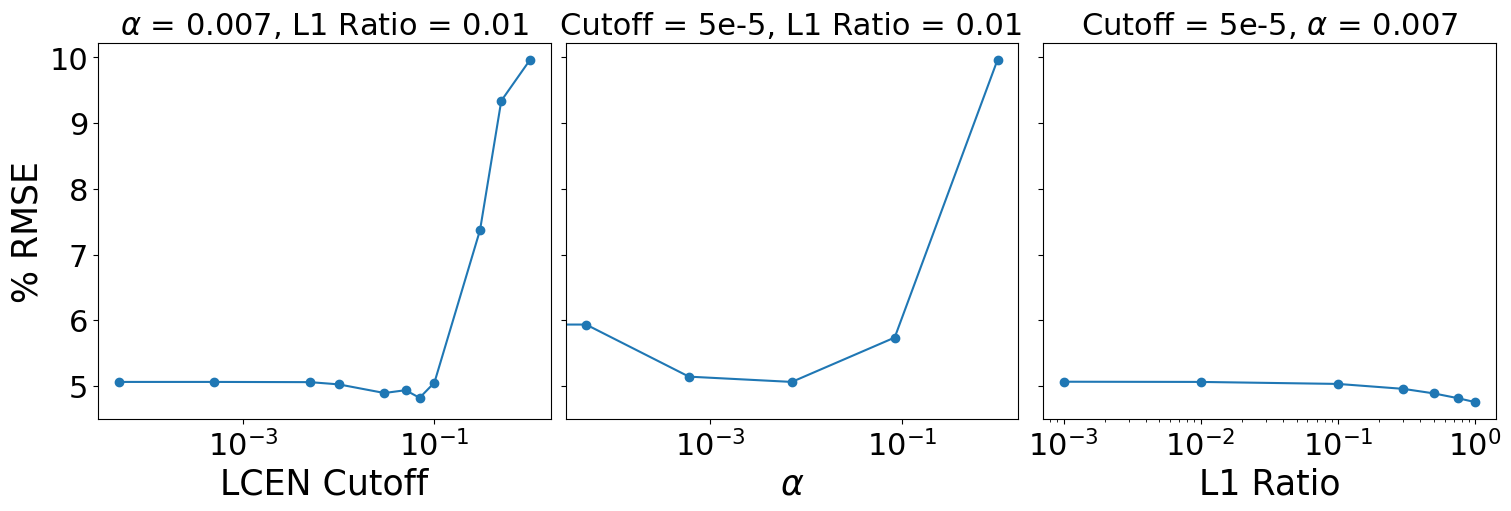

In [264]:
f, (ax1, ax2, ax3) = plt.subplots(1,3,figsize=(15,5), constrained_layout=True,sharey=True)
ax1.plot(cutoff_arr, results, marker='o')
ax1.set_xlabel('LCEN Cutoff')
ax1.set_ylabel('% RMSE')
ax1.set_xscale('log')

ax2.plot(alpharange, alpharesults, marker='o')
ax2.set_xlabel(r'$\alpha$')
ax2.set_xscale('log')

ax3.plot(l1_arr, lratio_results, marker='o')
ax3.set_xlabel(r'L1 Ratio')
ax3.set_xscale('log')

for ax in [ax1, ax2, ax3]:
    ax.tick_params(axis='both', labelsize=22)
    ax.xaxis.label.set_size(25)
    ax.yaxis.label.set_size(25)
    
ax1.set_title(r'$\alpha$ = 0.007, L1 Ratio = 0.01', fontsize=22)
ax2.set_title(r'Cutoff = 5e-5, L1 Ratio = 0.01', fontsize=22)
ax3.set_title(r'Cutoff = 5e-5, $\alpha$ = 0.007', fontsize=22)

